# Minor Project 4: Predictive Classification using Random Forest Ensembles

**Objective:** Build a classification model with a Random Forest, perform exploratory data analysis (EDA), preprocess data, and evaluate it using a confusion matrix, precision, recall, F1-score, ROC-AUC, and feature importance.

**Dataset used:** Breast Cancer Wisconsin dataset included with scikit-learn. This is a real-world binary classification dataset, so the notebook runs without downloading a file or requiring an API key. The target classes are **malignant** and **benign**.

> Before submission: run every cell from top to bottom in Google Colab, inspect the actual metrics and plots, and use the generated results in your report. Do not report metrics until the notebook has run.

## 1. Import libraries and load the dataset

The dataset is loaded from scikit-learn. This makes the notebook reproducible in Colab without manual Kaggle downloads. If your instructor specifically requires a Kaggle dataset, replace this loading section with the approved Kaggle dataset and update the target column.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    accuracy_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()

# In sklearn's dataset, 0 = malignant and 1 = benign.
# Keep the mapping explicit so plots and reports are easy to interpret.
target_names = {0: "malignant", 1: "benign"}
y = y.rename("target")

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("Feature count:", X.shape[1])
print("\nFirst five rows:")
display(df.head())
print("\nTarget class counts:")
display(y.map(target_names).value_counts().rename_axis("class").to_frame("count"))

Dataset shape: (569, 31)
Feature count: 30

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target class counts:


,count
class,
benign,357
malignant,212


## 2. Phase I — Exploratory Data Analysis (EDA)

Review data types, summary statistics, missing values, feature distributions, target balance, and feature correlations before training.

Data types:


,number of columns
data type,
float64,30
int64,1


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values per column (largest first):


,missing values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


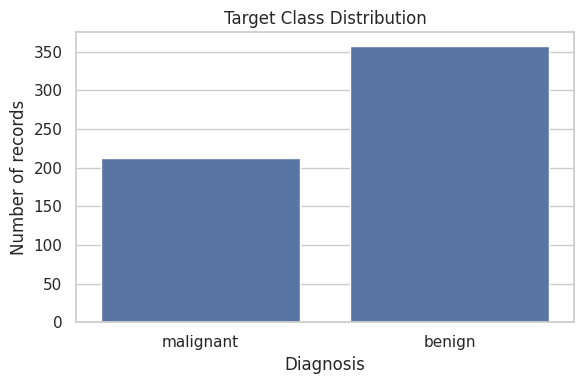

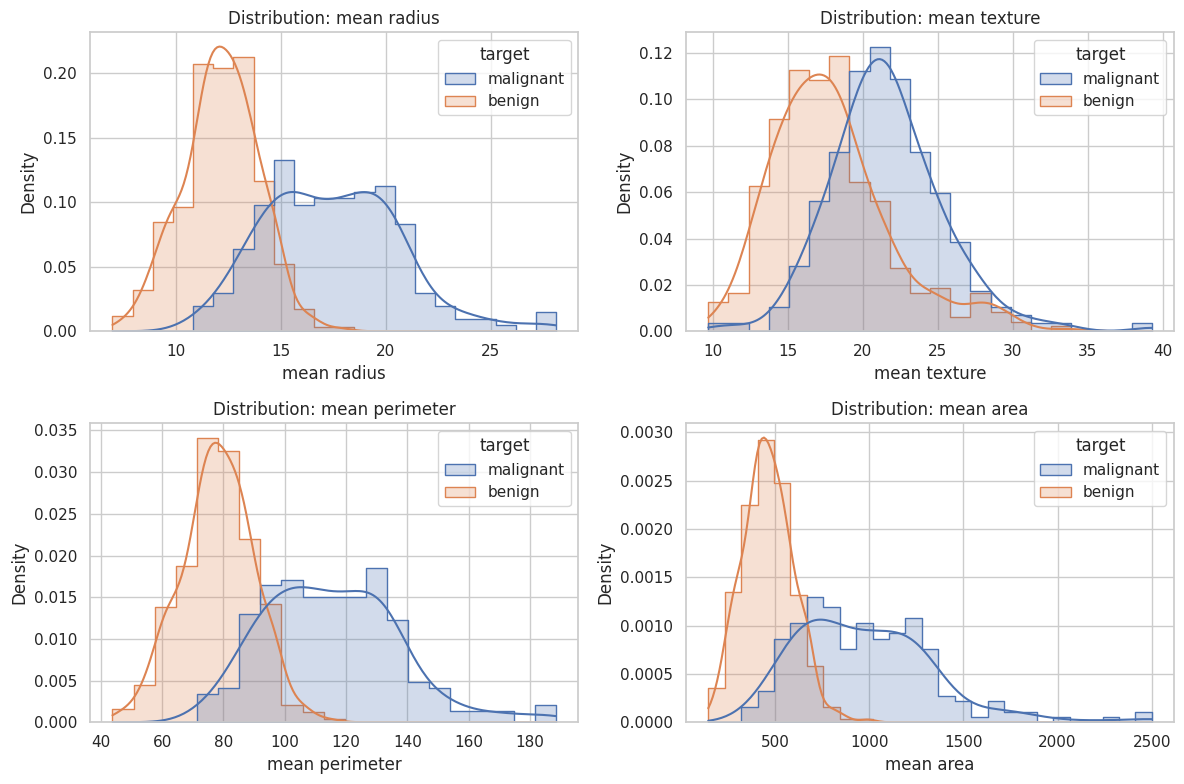

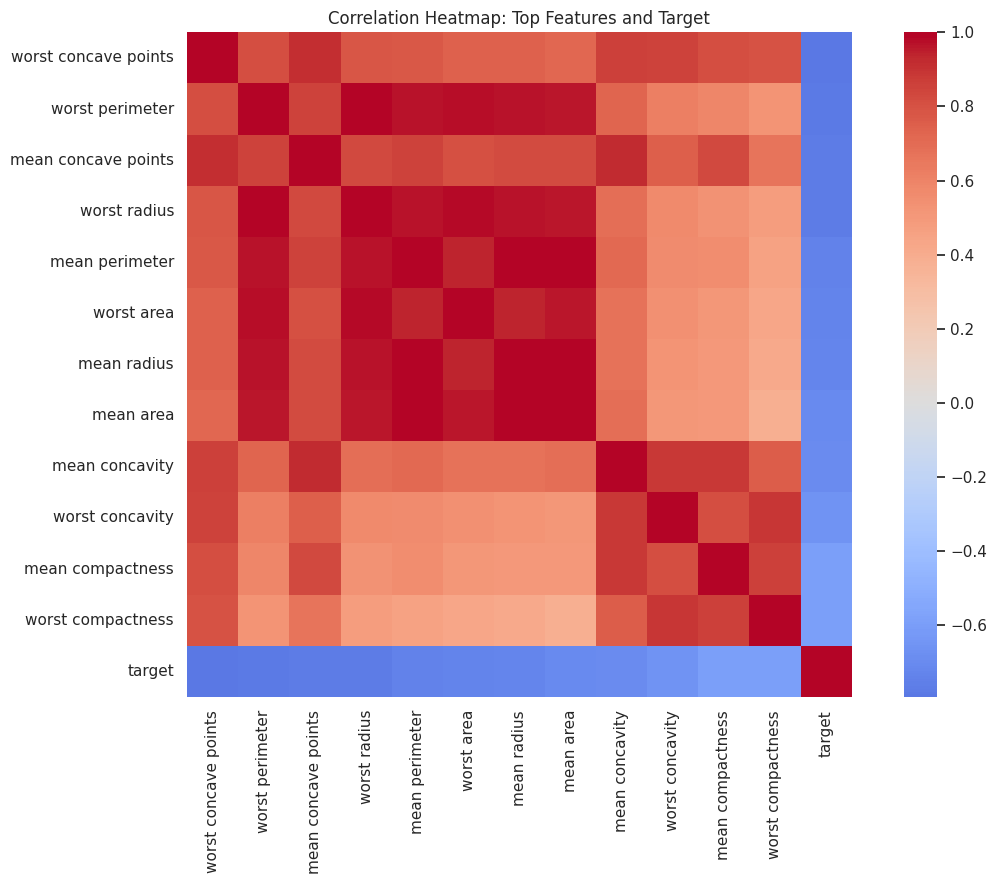

In [2]:
print("Data types:")
display(df.dtypes.value_counts().rename_axis("data type").to_frame("number of columns"))

print("Summary statistics:")
display(X.describe().T)

print("Missing values per column (largest first):")
missing_counts = df.isnull().sum().sort_values(ascending=False)
display(missing_counts.head(15).to_frame("missing values"))

plt.figure(figsize=(6, 4))
sns.countplot(x=y.map(target_names), order=["malignant", "benign"])
plt.title("Target Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# Plot selected feature distributions to keep the notebook readable.
selected_features = ["mean radius", "mean texture", "mean perimeter", "mean area"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected_features, axes.flat):
    sns.histplot(data=df, x=feature, hue=df["target"].map(target_names),
                 kde=True, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribution: {feature}")
plt.tight_layout()
plt.show()

# Correlation heatmap for the 12 features with the strongest absolute correlation
# to the target, plus the target itself. This avoids an unreadable 30-feature plot.
corr = df.corr(numeric_only=True)
top_corr_features = corr["target"].drop("target").abs().sort_values(ascending=False).head(12).index.tolist()
heatmap_cols = top_corr_features + ["target"]
plt.figure(figsize=(12, 9))
sns.heatmap(df[heatmap_cols].corr(), cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Correlation Heatmap: Top Features and Target")
plt.tight_layout()
plt.show()

### EDA interpretation guide

- Compare malignant and benign counts to assess class imbalance.
- Inspect the missing-value table. The selected dataset is typically complete, but the preprocessing pipeline below still handles missing values if they occur.
- Feature distributions show how selected measurements vary by diagnosis.
- Correlation indicates linear association, not causation. Correlated predictors can contain overlapping information.

## 3. Phase II — Preprocessing and train/test split

The dataset contains numeric features. A median imputer is included to handle missing numeric values. The pipeline also supports categorical columns with most-frequent imputation and one-hot encoding if a different dataset is used. We use an 80:20 stratified split so both classes are represented proportionally in train and test sets.

In [3]:
# Detect feature types so the preprocessing can be adapted to a CSV dataset later.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target proportions:")
display(y_train.map(target_names).value_counts(normalize=True).rename("proportion").to_frame())
print("Testing target proportions:")
display(y_test.map(target_names).value_counts(normalize=True).rename("proportion").to_frame())

print("Feature scaling: skipped. Random Forest uses decision-tree splits and is not distance-based, so standardization is generally unnecessary.")

Training samples: 455
Testing samples: 114
Training target proportions:


,proportion
target,
benign,0.626374
malignant,0.373626


Testing target proportions:


,proportion
target,
benign,0.631579
malignant,0.368421


Feature scaling: skipped. Random Forest uses decision-tree splits and is not distance-based, so standardization is generally unnecessary.


## 4. Phase III — Train the Random Forest model

**Hyperparameter choices**
- `n_estimators=300`: uses many trees to stabilize ensemble predictions while keeping training practical.
- `max_depth=None`: lets trees grow until stopping conditions are met; this can capture complex patterns, though it may overfit, so test-set evaluation is important.
- `class_weight="balanced"`: adjusts class weights based on class frequencies, which can help when classes are imbalanced.
- `random_state=42`: makes the train/test split and model results reproducible.

In [4]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # probability of class 1 = benign

print("Model training complete.")

Model training complete.


## 5. Phase IV — Required evaluation metrics

The confusion matrix uses the explicit class order **malignant, benign**. Precision describes how often predictions for a class are correct; recall describes how many actual members of a class are found. F1-score balances precision and recall. ROC-AUC measures ranking performance across thresholds; here the positive class is **benign**. For medical interpretation, pay special attention to malignant-class recall because missing malignant cases can be consequential.

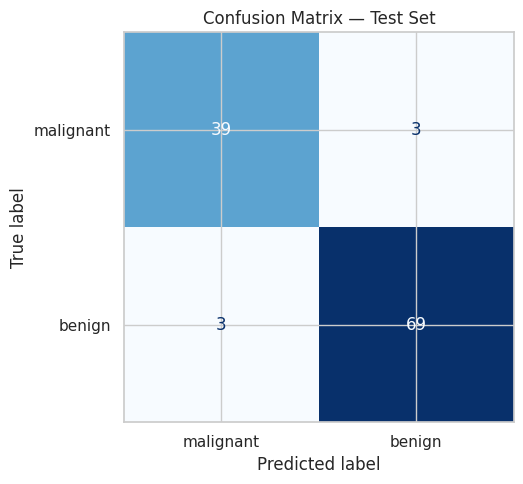

Accuracy:          0.9474
Macro Precision:   0.9435
Macro Recall:      0.9435
Macro F1-score:    0.9435
ROC-AUC (benign=1): 0.9937

Classification report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



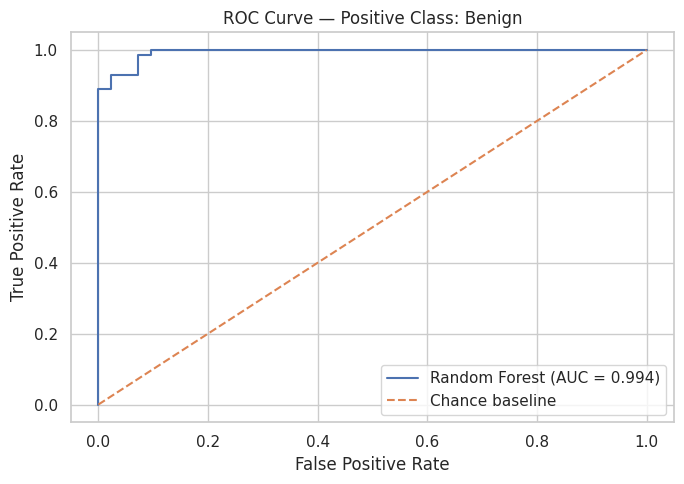

In [5]:
labels = [0, 1]
label_names = ["malignant", "benign"]

cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {precision_macro:.4f}")
print(f"Macro Recall:      {recall_macro:.4f}")
print(f"Macro F1-score:    {f1_macro:.4f}")
print(f"ROC-AUC (benign=1): {roc_auc:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=label_names, zero_division=0))

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Positive Class: Benign")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Feature importance

Feature importance from a Random Forest estimates how much each feature contributes to reducing impurity across the fitted trees. It is useful for model interpretation, but it does not prove causation and can distribute importance across correlated features.

,feature,importance
22,numeric__worst perimeter,0.145078
23,numeric__worst area,0.138975
27,numeric__worst concave points,0.109683
7,numeric__mean concave points,0.096527
20,numeric__worst radius,0.078583
0,numeric__mean radius,0.049770
6,numeric__mean concavity,0.049763
26,numeric__worst concavity,0.043556
2,numeric__mean perimeter,0.042546
13,numeric__area error,0.038818


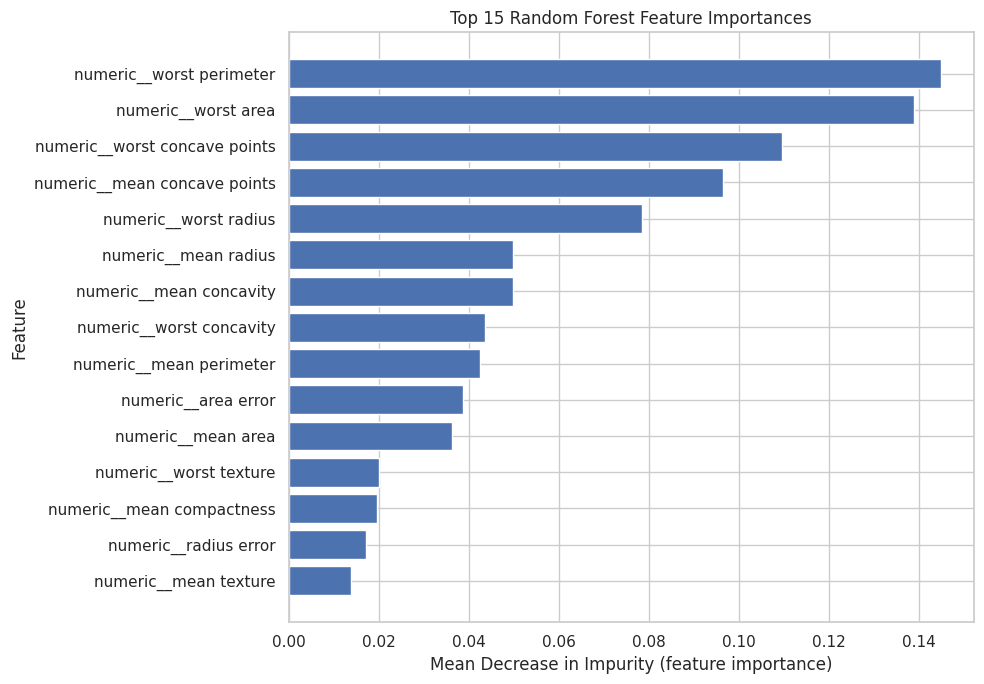

In [6]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

# Recover readable feature names after preprocessing.
try:
    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    transformed_feature_names = np.array([f"feature_{i}" for i in range(len(fitted_classifier.feature_importances_))])

importance_df = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": fitted_classifier.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(15))

top_n = 15
plot_df = importance_df.head(top_n).sort_values("importance", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Mean Decrease in Impurity (feature importance)")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## 7. Findings and discussion

Run the cells above and use the actual displayed values to complete this discussion. The next cell automatically prints a short, data-driven summary based on the test-set metrics; review it before submission.

In [7]:
print("RESULTS SUMMARY FOR REPORT")
print(f"- Test accuracy: {accuracy:.3f}")
print(f"- Macro precision: {precision_macro:.3f}")
print(f"- Macro recall: {recall_macro:.3f}")
print(f"- Macro F1-score: {f1_macro:.3f}")
print(f"- ROC-AUC (benign as positive class): {roc_auc:.3f}")

malignant_recall = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
benign_recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
print(f"- Malignant-class recall: {malignant_recall:.3f}")
print(f"- Benign-class recall: {benign_recall:.3f}")

if malignant_recall < 0.90:
    print("Interpretation: malignant recall is below 0.90; inspect false negatives and consider threshold tuning, class weighting, or further model evaluation.")
else:
    print("Interpretation: malignant recall is at least 0.90 on this test split; still inspect false negatives because this is a practice model, not a clinical diagnostic tool.")

print("\nTop five features:")
display(importance_df.head(5))

RESULTS SUMMARY FOR REPORT
- Test accuracy: 0.947
- Macro precision: 0.943
- Macro recall: 0.943
- Macro F1-score: 0.943
- ROC-AUC (benign as positive class): 0.994
- Malignant-class recall: 0.929
- Benign-class recall: 0.958
Interpretation: malignant recall is at least 0.90 on this test split; still inspect false negatives because this is a practice model, not a clinical diagnostic tool.

Top five features:


,feature,importance
22,numeric__worst perimeter,0.145078
23,numeric__worst area,0.138975
27,numeric__worst concave points,0.109683
7,numeric__mean concave points,0.096527
20,numeric__worst radius,0.078583


## 8. Conclusion

The project demonstrates an end-to-end Random Forest classification workflow: data inspection, EDA, missing-value handling, encoding-ready preprocessing, stratified 80:20 split, model fitting, evaluation, ROC analysis, and feature-importance visualization.

**Strengths:** Random Forest can model nonlinear relationships, combines many trees, and provides feature-importance estimates. It does not normally require feature scaling.

**Limitations:** A single train/test split may give an optimistic or pessimistic estimate; feature importance can be biased or split across correlated predictors; the model's predictions should not be treated as medical advice. This dataset is for educational ML practice only.

**Future improvements:** use cross-validation, tune `n_estimators` and `max_depth` with `GridSearchCV` or `RandomizedSearchCV`, compare Gradient Boosting, evaluate calibration and decision thresholds, and test on an independent dataset.

## 9. Submission checklist

- [ ] Run all cells in Google Colab from top to bottom.
- [ ] Confirm that all plots render and metrics are printed.
- [ ] Review the actual results and write your own brief interpretation.
- [ ] Rename the notebook with your name and project number.
- [ ] Download the notebook as `.ipynb`; optionally export a PDF report from Colab.
- [ ] If your instructor requires a Kaggle dataset specifically, substitute that dataset before submitting.